## Instructions

Use this notebook to download Tessera embeddings. You only need to do this once, or maybe not at all if referencing the embeddings that are already in HDFS.

Before you run this script, consider accessing the data files from Ian's HDFS directly. They are at:
```
/final/data/2025_foco_bbox_full.tif
/final/data/2025_foco_bbox_quant.tif
/final/data/SurfaceFuels_COWRA22.tif
```
and you can see them like:
```bash
hadoop fs -fs hdfs://sacramento.cs.colostate.edu:30141 -ls -R /final/data
```

In [21]:
import numpy as np
from geotessera import GeoTesseraZarr
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

In [3]:
gt = GeoTesseraZarr(cache_dir="./data")  # v1.1 dClimate Icechunk store
print(gt.dataset.name)
print(gt.years)  # [2017, ..., 2025]

1.1-dclimate
[2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [6]:
# Foco: (West, South, East, North)
# https://bboxfinder.com/#40.500000,-105.500000,40.900000,-104.800000
FOCO_BBOX = (-105.5, 40.5, -104.8, 40.9)

In [9]:
# An example embedding pixel for Fort Collins
vec, status = gt.probe(-105.08, 40.59, year=2025)
print(status)
print(vec.shape)
vec

valid
(128,)


array([ 1.2005413 , -0.6149114 , -0.96628934,  0.14640747,  0.35137793,
       -0.0292815 ,  1.4933562 , -0.05856299, -1.3176672 , -0.23425196,
        1.4055117 ,  1.2298228 ,  0.        ,  1.9325787 ,  1.9911417 ,
        2.1375492 , -0.93700784,  1.2883857 , -0.5563484 ,  1.0541338 ,
       -3.71875   ,  0.6734744 , -0.11712598, -0.5563484 , -1.2883857 ,
        0.23425196, -2.4010825 ,  0.96628934, -0.11712598, -0.73203737,
       -0.35137793, -0.99557084, -1.7861712 ,  1.8154527 ,  0.49778542,
        1.7861712 , -1.4055117 , -1.9911417 , -1.2591043 , -2.664616  ,
        0.0292815 ,  3.074557  ,  0.84916335, -0.20497046, -0.11712598,
        0.96628934, -2.4889271 ,  2.723179  , -0.87844485,  0.05856299,
       -1.4347932 ,  3.5723424 , -0.11712598,  0.96628934,  1.3762302 ,
       -1.1126968 , -0.6734744 , -2.3132381 , -0.0292815 , -2.3718011 ,
        1.2883857 ,  0.73203737,  2.4303641 , -1.9911417 , -0.23425196,
        1.4933562 , -2.0204232 , -0.17568897,  1.6983267 , -0.87

In [10]:
foco_embeddings, foco_transform, foco_crs = gt.read_region(FOCO_BBOX, year=2025)
foco_embeddings.shape, foco_transform, foco_crs

((4453, 5932, 128),
 Affine(10.0, 0.0, 457630.0,
        0.0, -10.0, 4527780.0),
 'EPSG:32613')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.8558073..3.2450788].


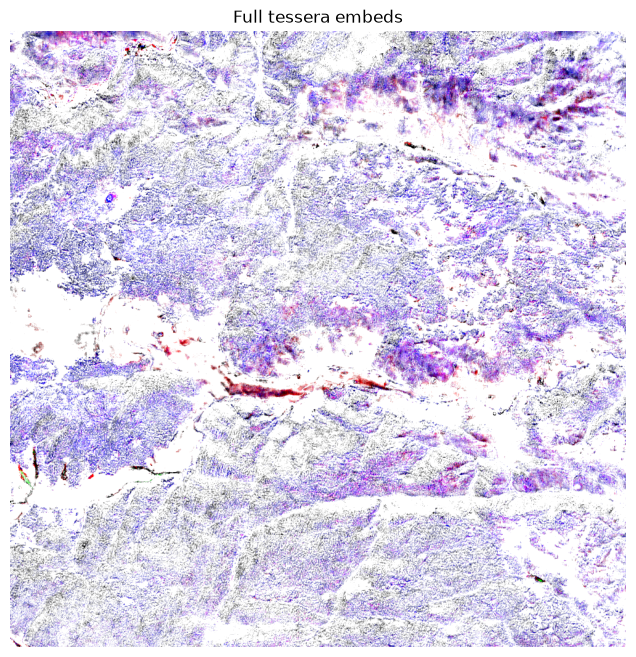

In [12]:
band = 28
plt.figure(figsize=(10, 8))
plt.imshow(foco_embeddings[:1000, :1000, band:band + 4])
plt.title("Full tessera embeds")
plt.axis("off")
plt.show()

In [15]:
quant_embeddings, quant_scales, quant_transform, quant_crs = gt.read_region_quantized(FOCO_BBOX, year=2025)
quant_embeddings.shape, quant_scales.shape, quant_transform, quant_crs

((4453, 5932, 128),
 (4453, 5932),
 Affine(10.0, 0.0, 457630.0,
        0.0, -10.0, 4527780.0),
 'EPSG:32613')

In [ ]:
quant_embeddings[1, 1, :]  # int8

array([  81,  -39,  -47,    7,   45,    9,  -34,  -13,   -9,   36,   57,
         38,    7,   12,   -4,   83,  -42,   29,   37,   31,  -79,  -43,
          0,  -85,   19,  -26,  -18,   27,   14,   -4,   59,   -7,  -78,
        -30,   24,  -16,  -31,   29,  -23,   -4,   48,   27,   39,  -69,
        -39,   41,   -3,   57,   16,  -35,   33,   27,  -11,   20,  -10,
          6,  -16,   18,  -46,  -33,   21,    5,  -15,  -76,  -24,   18,
        -32,  -21,   37,  -35,  -30,   60,    7,   26,  -55,   29,   35,
         77, -127,   14,  -23,   -2,   -2,  -17,  -33,  -37,   -6,  -55,
        -87,   12,   27,  -36,    6,  -41,    7,  -14,   22,   32,   19,
         11,   45,  -36,  -44,   36,   98,   10,  -21,  -10,   48,  -14,
        -74,    9,    6,   46,   22,  -45,  -41,    1,  -50,    6,    8,
         58,  -10,  -16,   74,   56,   -2,  -18], dtype=int8)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-127..119].


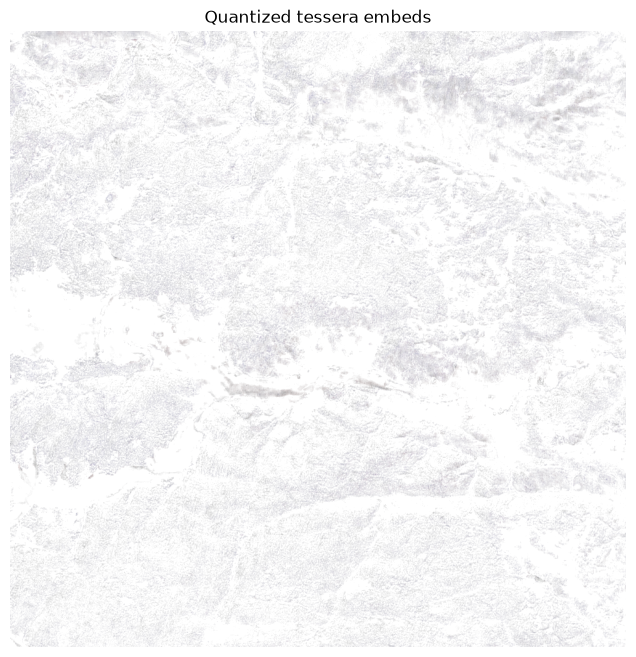

In [16]:
band = 28
plt.figure(figsize=(10, 8))
plt.imshow(quant_embeddings[:1000, :1000, band:band + 4])
plt.title("Quantized tessera embeds")
plt.axis("off")
plt.show()

In [14]:
def save_tif(multiband_image, transform, crs, file_name="output.tif"):
    """
    `multiband_image` should have the shape: (bands, height, width)

    This creates 256x256 tiles internal to the GeoTIF for each band dimension.
    """

    print(f"saving multiband_image of shape: {multiband_image.shape}")
    bands, height, width = multiband_image.shape

    with rasterio.open(file_name,
                        mode="w",
                        driver="GTiff",
                        crs=crs,
                        transform=transform,
                        width=width,
                        height=height,
                        count=bands,
                        dtype=multiband_image.dtype,
                        tiled=True,
                        blockxsize=256,
                        blockysize=256) as dst:
        dst.write(multiband_image)

def read_geo_tif(file_name):
    with rasterio.open(file_name, mode="r") as src:
        # Shape: (bands, height, width)
        src_arr = src.read()

        print("Array shape (bands, height, width):", src_arr.shape)
        print("CRS:", src.crs)
        print("Transform:", src.transform)
        print("It tiled?", src.is_tiled)

        # For tiled files, this corresponds to (TileLength, TileWidth)
        print("Block shapes:", len(src.block_shapes))

    return src_arr, src.transform, src.crs

In [22]:
Path("data").mkdir(parents=True, exist_ok=True)
save_tif(np.permute_dims(foco_embeddings, axes=(2, 0, 1)), foco_transform, \
         foco_crs, file_name="./data/2025_foco_bbox_full.tif")

saving multiband_image of shape: (128, 4453, 5932)


In [23]:
save_tif(np.permute_dims(quant_embeddings, axes=(2, 0, 1)), quant_transform, \
         quant_crs, file_name="./data/2025_foco_bbox_quant.tif")

saving multiband_image of shape: (128, 4453, 5932)


## NOTE

After saving the above files, move them into HDFS and delete them from your NFS directory asap so you do not stay over your storage quota.